# Inspect the published citation results

Checks and explores what the pipeline has published. It validates `Results/v4` when it is there, and
`Results/v3` either way: the v3 copy written from v4, or the legacy v3 published before v4.
It calls no citation APIs. Results are read from this clone or straight from GitHub, at any branch,
tag or commit.

1. **Validation**: a PASS / WARN / FAIL / INFO table. v4 is checked against the format in the
   README, plus integrity, the counting rules, the manifest and the reconciliation. v3 is checked
   for parity between the CSV and the JSON and for data quality; when v4 exists, it is also checked
   against v4.
2. **Overview**: per data centre, counted citations and related links, the sources they come from,
   exclusions, metadata completeness, the most-cited datasets, citations by UK fiscal year, and
   what is new since a given date.
3. **One dataset**: `show_dataset(doi)` lists its citations, its related links and its DataCite
   reconciliation.
4. **Compare with another version**: how counts per dataset changed, and `compare_dataset(doi)`
   for new, gone and unchanged citing works. Comparing a v4 version with a legacy v3 one counts
   like for like: legacy rows are classified with the v4 rules before counting.

## Settings

In [1]:
#@title Settings  { display-mode: "form" }
# Where to read results from: a folder ("Results" in this clone) or GitHub at a ref.
SOURCE      = "local"            #@param ["local", "github"]
LOCAL_DIR   = "Results"          #@param {type:"string"}
REPO        = "NERC-EDS/citationNotebook"
REF         = "main"             #@param {type:"string"}

# Optional second version to compare with: a folder, or a git ref of REPO on GitHub. Leave both empty to skip.
COMPARE_DIR = ""                 #@param {type:"string"}
COMPARE_REF = ""                 #@param {type:"string"}   # e.g. a commit before v4, such as d7c8b3a

# Upstream v3 files to compare the v3 file formats with (section 1c): what the EDS citation API reads.
UPSTREAM_REPO = "NERC-EDS/citationNotebook"
UPSTREAM_REF  = "main"           #@param {type:"string"}
UPSTREAM_DIR  = ""               #@param {type:"string"}   # or a Results folder holding upstream's v3/

FOCUS_CENTRE   = "NGDC"          #@param ["NGDC", "BODC", "CEDA", "EIDC", "PDC"]
INSPECT_DOI    = ""              #@param {type:"string"}   # empty = the focus centre's most-cited dataset
NEW_SINCE      = ""              #@param {type:"string"}   # YYYY-MM-DD; empty = 14 days before the latest last_seen
FY_START_MONTH = 4                # UK fiscal year starts in April
TOP_N          = 10
OUTPUT_DIR     = "inspect_outputs"

In [2]:
#@title Imports and helpers  { display-mode: "form" }
import hashlib, io, json, os, re
from collections import Counter
from datetime import date, timedelta
from pathlib import Path
from urllib.parse import parse_qsl, unquote, urlencode, urlsplit, urlunsplit

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
os.makedirs(OUTPUT_DIR, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10,
})
CENTRES = ["BODC", "CEDA", "EIDC", "NGDC", "PDC"]
CENTRE_NAMES = {
    "BODC": "British Oceanographic Data Centre (BODC)", "CEDA": "Centre for Environmental Data Analysis (CEDA)",
    "EIDC": "Environmental Information Data Centre (EIDC)", "NGDC": "National Geoscience Data Centre (NGDC)",
    "PDC": "Polar Data Centre (PDC)",
}
NAME_TO_CODE = {v: k for k, v in CENTRE_NAMES.items()}
# Related-link classes in display order; the counted ones first.
CLASSES = ["citation", "supplement", "documentation", "other", "dataset-link", "version-or-part", "similarity"]
COUNTED_CLASSES = {"citation", "supplement"}
USE_CLASSES = {"citation", "supplement", "documentation", "other"}
CLASS_COLOUR = {"citation": SERIES[0], "supplement": "#86b6ef", "documentation": SERIES[2], "other": "#9ad9c1",
                "dataset-link": SERIES[3], "version-or-part": "#f4c869", "similarity": SERIES[1]}
REASONS = {"self-link", "comment", "peer-review", "conference-abstract", "gbif-download", "predates-data"}
PLACEHOLDERS = {"info not given", "not a doi", "unknown repository", "api request failed", "error occurred"}
FORMATTER_ERRORS = re.compile(r"^unknown style|^doi not found|metadata could not be retrieved|^resource not found|"
                              r"^too many requests|^service unavailable|^internal server error|<html|<!doctype|"
                              r"^\s*[{\[]|style-not-found", re.I)
DOI_RE = re.compile(r"10\.\d{4,9}/[^\s?#]+", re.I)
DATACITE_RELATIONS = {
    "IsCitedBy", "Cites", "IsSupplementTo", "IsSupplementedBy", "IsContinuedBy", "Continues", "IsDescribedBy",
    "Describes", "HasMetadata", "IsMetadataFor", "HasVersion", "IsVersionOf", "IsNewVersionOf", "IsPreviousVersionOf",
    "IsPartOf", "HasPart", "IsReferencedBy", "References", "IsDocumentedBy", "Documents", "IsCompiledBy", "Compiles",
    "IsVariantFormOf", "IsOriginalFormOf", "IsIdenticalTo", "IsReviewedBy", "Reviews", "IsDerivedFrom", "IsSourceOf",
    "IsRequiredBy", "Requires", "IsObsoletedBy", "Obsoletes", "HasAmongTopNSimilarDocuments",
}


def normalise_id(value):
    """The pipeline's identifier normalisation (citations/ids.py), so v3 and v4 rows can be matched."""
    text = "" if value is None or (isinstance(value, float) and value != value) else str(value).strip()
    if not text or text.lower() in PLACEHOLDERS:
        return None
    path = urlsplit(text).path if re.match(r"https?://", text, re.I) else text
    m = DOI_RE.search(unquote(path))
    if m:
        doi = m.group(0).rstrip(".,;")
        if doi.endswith(")") and doi.count(")") > doi.count("("):
            doi = doi[:-1]
        return doi.lower()
    if re.match(r"https?://", text, re.I):
        p = urlsplit(text)
        host = p.netloc.lower()
        host = host[4:] if host.startswith("www.") else host
        query = urlencode([(k, v) for k, v in parse_qsl(p.query, keep_blank_values=True)
                           if not re.match(r"^(utm_|fbclid$|gclid$)", k, re.I)])
        return urlunsplit(("https", host, p.path.rstrip("/") if p.path not in ("", "/") else "", query, ""))
    return text


def iso_date(value):
    """ISO date string from ISO or D/M/YYYY text, else None."""
    text = "" if value is None or (isinstance(value, float) and value != value) else str(value).strip()
    m = re.match(r"^(\d{4})(?:-(\d{1,2}))?(?:-(\d{1,2}))?", text)
    if m:
        y, mo, d = m.groups()
        return f"{y}-{int(mo):02d}-{int(d):02d}" if d else (f"{y}-{int(mo):02d}" if mo else y)
    m = re.match(r"^(\d{1,2})/(\d{1,2})/(\d{4})$", text)
    if m:
        d, mo, y = m.groups()
        return f"{y}-{int(mo):02d}-{int(d):02d}"
    return None


def fy_label(iso, start=FY_START_MONTH):
    if not iso or len(iso) < 7:
        return None
    y, m = int(iso[:4]), int(iso[5:7])
    y = y if m >= start else y - 1
    return f"FY{y}/{str(y + 1)[-2:]}"


def short(s, n=70):
    s = "" if s is None or (isinstance(s, float) and s != s) else str(s)
    return s if len(s) <= n else s[: n - 1] + "…"

## 1. Load

In [3]:
#@title Read the files  { display-mode: "form" }
V4_FILES = ["datasets.csv", "datasets.json", "links.csv", "links.jsonl", "works.csv", "works.json",
            "reconciliation.csv", "manifest.json"]
V3_FILES = ["latest_results.csv", "latest_results.json", "filtered_out_df.csv"]


def fetcher(local_dir=None, ref=None):
    """A function path -> bytes or None (missing), for a folder or GitHub at a ref."""
    if local_dir:
        root = Path(local_dir)
        return (lambda p: (root / p).read_bytes() if (root / p).exists() else None), f"folder {root.resolve()}"
    session = requests.Session()

    def get(p):
        r = session.get(f"https://raw.githubusercontent.com/{REPO}/{ref}/Results/{p}", timeout=120)
        if r.status_code == 404:
            return None
        r.raise_for_status()
        return r.content
    return get, f"github.com/{REPO} at {ref}"


def read_csv(b, encoding="utf-8"):
    return pd.read_csv(io.BytesIO(b), dtype=str, keep_default_na=False, encoding=encoding)


def load(get, label):
    res = {"label": label, "v4": None, "v3": None}
    raw = {f"v4/{f}": get(f"v4/{f}") for f in V4_FILES}
    if raw["v4/links.csv"] is not None:
        v4 = {"raw": raw}
        for name in ("datasets", "links", "works", "reconciliation"):
            b = raw[f"v4/{name}.csv"]
            v4[name] = read_csv(b) if b is not None else None
        v4["manifest"] = json.loads(raw["v4/manifest.json"]) if raw["v4/manifest.json"] else None
        res["v4"] = v4
    b = get("v3/latest_results.csv")
    if b is not None:
        v3 = {"csv": read_csv(b, "utf-8-sig")}
        j = get("v3/latest_results.json")
        v3["json"] = json.loads(j) if j else None
        f = get("v3/filtered_out_df.csv")
        v3["filtered"] = read_csv(f, "utf-8-sig") if f else None
        # Legacy = published by the v3 notebooks. Their tell-tales: Scholix relations ("IsRelatedTo/cites")
        # and D/M/YYYY dates. (filtered_out_df.csv has the same columns either way: v4 writes v3's.)
        csv = v3["csv"]
        v3["legacy"] = bool(csv.relation_type_id.str.contains("/|similar", case=False).any()
                            or csv.publication_date.str.fullmatch(r"\d{1,2}/\d{1,2}/\d{4}").any())
        res["v3"] = v3
    if not (res["v4"] or res["v3"]):
        raise FileNotFoundError(f"No Results/v4/links.csv or Results/v3/latest_results.csv at {label}. "
                                "Check the folder, or that the ref exists in the repository.")
    return res


get, label = fetcher(LOCAL_DIR if SOURCE == "local" else None, REF if SOURCE == "github" else None)
R = load(get, label)
summary_lines = [f"**Source:** {R['label']}"]
if R["v4"]:
    m = R["v4"]["manifest"] or {}
    summary_lines.append(f"**v4:** {len(R['v4']['links']):,} links, {len(R['v4']['datasets']):,} datasets, "
                         f"{len(R['v4']['works']):,} works; generated {m.get('generated_at', '?')} by code {m.get('code_version', '?')}")
else:
    summary_lines.append("**v4:** not present at this source")
if R["v3"]:
    summary_lines.append(f"**v3:** {len(R['v3']['csv']):,} rows ({'legacy, from the v3 pipeline' if R['v3']['legacy'] else 'written from v4'})")
display(Markdown("  \n".join(summary_lines)))

**Source:** folder C:\GIT\citationNotebook\Results  
**v4:** 28,000 links, 6,366 datasets, 15,849 works; generated 2026-10-07T19:40:13Z by code 4.0.0  
**v3:** 8,204 rows (written from v4)

---
# Part 1 — Validation

**FAIL**: the files are structurally wrong or break a rule the format guarantees. **WARN**: data
quality that changes counts or what users see. **INFO**: worth knowing. The rows behind each
non-passing check are kept in `details[...]` and written to `OUTPUT_DIR`.

In [4]:
#@title Validation framework  { display-mode: "form" }
checks, details = [], {}


def check(cid, name, level, failing, note=""):
    n = len(failing) if isinstance(failing, pd.DataFrame) else int(failing)
    if isinstance(failing, pd.DataFrame):
        details[cid] = failing
    checks.append({"id": cid, "check": name, "status": "PASS" if n == 0 else level, "n": n, "note": note})


def summarise(prefix=None):
    df = pd.DataFrame(checks)
    if prefix:
        df = df[df.id.str.startswith(prefix)]
    order = {"FAIL": 0, "WARN": 1, "INFO": 2, "PASS": 3}
    return df.sort_values(["status", "id"], key=lambda s: s.map(order) if s.name == "status" else s).reset_index(drop=True)

## 1a. v4

In [5]:
#@title Check Results/v4  { display-mode: "form" }
V4_COLUMNS = {
    "datasets": ["doi", "data_centre", "data_centre_name", "publisher", "title", "publication_year",
                 "resource_type_general", "registered", "authors", "counted_citations", "related_links",
                 "excluded_links", "datacite_citation_count", "first_cited"],
    "links": ["link_id", "data_doi", "data_centre", "citing_id", "citing_id_type", "relation_type", "relation_class",
              "counted", "status", "exclusion_reason", "sources", "source_relations", "first_seen", "last_seen"],
    "works": ["citing_id", "citing_id_type", "title", "work_type", "container_title", "publisher", "issued",
              "issued_precision", "authors", "citation_text", "metadata_source", "fetched_at"],
    "reconciliation": ["doi", "data_centre", "datacite_citation_count", "datacite_links_harvested",
                       "missing_vs_datacite", "datacite_links_counted", "datacite_links_dataset_link",
                       "datacite_links_excluded", "datacite_links_other_class", "pipeline_counted",
                       "pipeline_counted_not_in_datacite", "pipeline_all_links", "complete"],
}

if not R["v4"]:
    display(Markdown("_No Results/v4 at this source; skipping the v4 checks._"))
else:
    V = R["v4"]
    ds, ln, wk, rc, mf = V["datasets"], V["links"], V["works"], V["reconciliation"], V["manifest"]

    # -- files and columns --------------------------------------------------
    missing_files = [f for f in V4_FILES if V["raw"][f"v4/{f}"] is None]
    check("V4-S1", "All v4 files are present", "FAIL", len(missing_files), ", ".join(missing_files))
    for i, (name, cols) in enumerate(V4_COLUMNS.items(), 2):
        df = V.get(name)
        got = list(df.columns) if df is not None else []
        check(f"V4-S{i}", f"{name}.csv has the documented columns, in order", "FAIL", int(got != cols),
              "" if got == cols else f"missing {[c for c in cols if c not in got]}, extra {[c for c in got if c not in cols]}")

    # -- CSV and JSON agree --------------------------------------------------
    def json_rows(name, lines=False):
        b = V["raw"].get(f"v4/{name}")
        if b is None:
            return None
        text = b.decode("utf-8")
        return [json.loads(l) for l in text.splitlines() if l.strip()] if lines else json.loads(text)
    for cid, csv_df, jname, key, lines in [("V4-P1", ln, "links.jsonl", "link_id", True),
                                           ("V4-P2", ds, "datasets.json", "doi", False),
                                           ("V4-P3", wk, "works.json", "citing_id", False)]:
        rows = json_rows(jname, lines)
        if rows is None:
            continue
        a, b = set(csv_df[key]), {r[key] for r in rows}
        check(cid, f"{jname} has the same records as the CSV", "FAIL", len(a ^ b),
              f"{len(a - b)} only in CSV, {len(b - a)} only in JSON" if a ^ b else "")

    # -- identifiers and integrity -------------------------------------------
    sha = (ln.data_doi + "|" + ln.citing_id).map(lambda s: hashlib.sha1(s.encode()).hexdigest())
    check("V4-I1", "link_id is unique and is sha1(data_doi|citing_id)", "FAIL",
          ln[(sha != ln.link_id) | ln.link_id.duplicated(keep=False)])
    check("V4-I2", "One link per dataset × citing work", "FAIL", ln[ln.duplicated(["data_doi", "citing_id"], keep=False)])
    check("V4-I3", "Every link's dataset is in datasets.csv", "FAIL", ln[~ln.data_doi.isin(ds.doi)])
    check("V4-I4", "Every citing work is in works.csv", "WARN", ln[~ln.citing_id.isin(wk.citing_id)])
    check("V4-I5", "Dataset DOIs are lower-case 10.5285 DOIs", "FAIL",
          ds[~ds.doi.str.fullmatch(r"10\.5285/[^\sA-Z]+")])
    kind_ok = np.select(
        [ln.citing_id_type == "doi", ln.citing_id_type == "url", ln.citing_id_type.isin(["pmid", "pmc", "handle"])],
        [ln.citing_id.str.fullmatch(r"10\.\d{4,9}/[^\sA-Z]+"), ln.citing_id.str.startswith("https://"),
         ln.citing_id.str.match(r"^(pmid|pmc|hdl):")], False).astype(bool)
    check("V4-I6", "citing_id matches citing_id_type (lower-case DOI, canonical https URL, pmid:/pmc:/hdl:)",
          "FAIL", ln[~kind_ok])
    check("V4-I7", "data_centre is one of the five centres or empty", "FAIL",
          ds[~ds.data_centre.isin(CENTRES + [""])])
    known = ln.data_doi.isin(ds.doi)
    check("V4-I8", "data_centre in links agrees with datasets", "FAIL",
          ln[known & (ln.data_centre != ln.data_doi.map(ds.set_index("doi").data_centre))])

    # -- vocabularies and the counting rules -----------------------------------
    check("V4-R1", "relation_class is a known class", "FAIL", ln[~ln.relation_class.isin(CLASSES)])
    check("V4-R2", "relation_type is in the DataCite vocabulary", "FAIL", ln[~ln.relation_type.isin(DATACITE_RELATIONS)])
    check("V4-R3", "status is included/excluded; exclusion_reason is set exactly when excluded", "FAIL",
          ln[~ln.status.isin(["included", "excluded"]) | ((ln.status == "excluded") != (ln.exclusion_reason != "")) |
             ((ln.exclusion_reason != "") & ~ln.exclusion_reason.isin(REASONS))])
    expect_counted = (ln.status == "included") & ln.relation_class.isin(COUNTED_CLASSES)
    check("V4-R4", "counted = included citation or supplement", "FAIL", ln[(ln.counted == "true") != expect_counted])
    nerc = ln.citing_id.str.startswith("10.5285/")
    check("V4-R5", "A NERC dataset citing a dataset is a dataset-link, never a counted citation", "FAIL",
          ln[nerc & ln.relation_class.isin(USE_CLASSES)])
    check("V4-R6", "dataset-link is only used when the other work is a NERC dataset", "FAIL",
          ln[(ln.relation_class == "dataset-link") & ~nerc])
    srcs = ln.sources.map(json.loads)
    rels = ln.source_relations.map(json.loads)
    check("V4-R7", "Every link lists its sources, and source_relations covers the same sources", "FAIL",
          ln[(srcs.map(len) == 0) | (srcs.map(set) != rels.map(lambda d: set(d)))])

    # -- dates and the pre-dates rule --------------------------------------------
    iso_ok = lambda s: s.str.fullmatch(r"\d{4}(-\d{2}(-\d{2})?)?") | (s == "")
    check("V4-T1", "first_seen and last_seen are ISO dates, first_seen <= last_seen", "FAIL",
          ln[~ln.first_seen.str.fullmatch(r"\d{4}-\d{2}-\d{2}") | ~ln.last_seen.str.fullmatch(r"\d{4}-\d{2}-\d{2}") |
             (ln.first_seen > ln.last_seen)])
    run_day = ((mf or {}).get("generated_at") or "9999")[:10]
    check("V4-T5", f"No link is first or last seen after the run ({run_day})", "WARN",
          ln[(ln.first_seen > run_day) | (ln.last_seen > run_day)])
    prec = wk.issued.str.len().map({4: "year", 7: "month", 10: "day"}).fillna("")
    check("V4-T2", "works.issued is ISO and its precision matches", "FAIL",
          wk[~iso_ok(wk.issued) | ((wk.issued != "") & (prec != wk.issued_precision))])
    tol = ((mf or {}).get("settings") or {}).get("predates_tolerance_years", 2)
    work_year = pd.to_numeric(ln.citing_id.map(wk.set_index("citing_id").issued).str[:4], errors="coerce")
    data_year = pd.to_numeric(ln.data_doi.map(ds.set_index("doi").publication_year), errors="coerce")
    breaks = ln.relation_class.isin(USE_CLASSES) & ((data_year - work_year) >= tol)
    bad = breaks & (ln.status == "included")
    check("V4-T3", f"Included use-of-data links do not pre-date the dataset by {tol}+ years", "WARN",
          ln[bad].assign(work_year=work_year[bad].values, data_year=data_year[bad].values),
          "a work's metadata may have changed since the merge")
    check("V4-T4", "Links excluded as predates-data really pre-date it", "WARN",
          ln[(ln.exclusion_reason == "predates-data") & ~breaks])

    # -- content -------------------------------------------------------------------
    text_cols = {"links": ln, "works": wk, "datasets": ds}
    ph = sum(int(df[c].str.strip().str.lower().isin(PLACEHOLDERS).sum()) for df in text_cols.values() for c in df.columns)
    check("V4-C1", "No placeholder values ('Info not given', 'not a doi', …) — empty means null", "FAIL", ph)
    counted_works = wk[wk.citing_id.isin(ln.citing_id[ln.counted == "true"])]
    check("V4-C2", "Counted citing works have a citation string", "WARN", counted_works[counted_works.citation_text == ""])
    check("V4-C3", "No formatter error messages stored as citation strings", "FAIL",
          wk[wk.citation_text.str.contains(FORMATTER_ERRORS, na=False)])
    check("V4-C4", "Counted citing works have a title", "WARN", counted_works[counted_works.title == ""])
    bad_json = [c for df, cols in ((ds, ["authors"]), (wk, ["authors"])) for c in cols
                if not df[c].map(lambda v: v == "" or isinstance(json.loads(v), list)).all()]
    check("V4-C5", "authors columns are JSON arrays", "FAIL", len(bad_json))

    # -- dataset totals, manifest, reconciliation -------------------------------------
    calc = pd.DataFrame({
        "counted": (ln.counted == "true").groupby(ln.data_doi).sum(),
        "related": ((ln.status == "included") & (ln.counted == "false")).groupby(ln.data_doi).sum(),
        "excluded": (ln.status == "excluded").groupby(ln.data_doi).sum(),
    }).reindex(ds.doi).fillna(0).astype(int)
    stated = ds.set_index("doi")[["counted_citations", "related_links", "excluded_links"]].astype(int)
    stated.columns = calc.columns
    check("V4-D1", "datasets.csv counts agree with links.csv", "FAIL",
          stated[(stated != calc).any(axis=1)].join(calc, rsuffix="_from_links").reset_index())
    if mf:
        c = mf.get("counts", {})
        diffs = {
            "links": (c.get("links"), len(ln)), "counted_links": (c.get("counted_links"), int((ln.counted == "true").sum())),
            "datasets": (c.get("datasets"), len(ds)), "works": (c.get("works"), len(wk)),
            "links_by_class": (c.get("links_by_class"), ln.relation_class.value_counts().to_dict()),
            "links_by_status": (c.get("links_by_status"), ln.status.value_counts().to_dict()),
        }
        bad = {k: v for k, v in diffs.items() if v[0] != v[1]}
        check("V4-M1", "manifest.json counts match the files", "FAIL", len(bad), "; ".join(bad))
        g = mf.get("guards", {})
        check("V4-M2", "Published without guard problems", "WARN", len(g.get("problems") or []),
              ("FORCED: " if g.get("forced") else "") + " | ".join(g.get("problems") or []))
        check("V4-M3", "Guard warnings at publish time", "INFO", len(g.get("warnings") or []), " | ".join(g.get("warnings") or []))
        stale = [s for s, info in (mf.get("sources") or {}).items() if info.get("stale") and info.get("good_run_id")]
        check("V4-M4", "No source's harvest was stale when published", "WARN", len(stale), ", ".join(stale))
        recon = mf.get("reconciliation") or {}
        thr = (mf.get("settings") or {}).get("reconcile_threshold", 0.05)
        check("V4-M5", f"Reconciliation with DataCite incomplete for at most {thr:.0%} of DataCite-cited datasets", "WARN",
              int((recon.get("incomplete_share") or 0) > thr),
              f"{recon.get('incomplete_datasets')} of {recon.get('datacite_cited_datasets')} incomplete")
    if rc is not None and len(rc):
        check("V4-M6", "reconciliation.csv pipeline_counted agrees with datasets.csv", "FAIL",
              rc[rc.pipeline_counted.astype(int) != rc.doi.map(calc.counted).fillna(0).astype(int)])
    display(summarise("V4"))

,id,check,status,n,note
0,V4-C1,"No placeholder values ('Info not given', 'not a doi', …) — empty means null",FAIL,17,
1,V4-C2,Counted citing works have a citation string,WARN,57,
2,V4-C4,Counted citing works have a title,WARN,57,
3,V4-C3,No formatter error messages stored as citation strings,PASS,0,
4,V4-C5,authors columns are JSON arrays,PASS,0,
5,V4-D1,datasets.csv counts agree with links.csv,PASS,0,
6,V4-I1,link_id is unique and is sha1(data_doi|citing_id),PASS,0,
7,V4-I2,One link per dataset × citing work,PASS,0,
8,V4-I3,Every link's dataset is in datasets.csv,PASS,0,
9,V4-I4,Every citing work is in works.csv,PASS,0,


## 1b. v3

In [6]:
#@title Check Results/v3  { display-mode: "form" }
V3_COLUMNS = ["data_doi", "data_publisher", "data_title", "data_publication_year", "data_authors", "relation_type_id",
              "publication_doi", "publication_title", "publication_date", "publication_authors",
              "citation_event_source", "pub_publisher", "publication_type", "publicationYear", "PubCitationStr",
              "data_doi_url", "publication_doi_url", "date_added"]

if not R["v3"]:
    display(Markdown("_No Results/v3 at this source._"))
else:
    c = R["v3"]["csv"].copy()
    c["pair"] = c.data_doi.str.strip().str.lower() + "|" + c.publication_doi.map(normalise_id).fillna("")
    check("V3-S1", "latest_results.csv has the 18 v3 columns, in order", "FAIL", int(list(c.columns[:18]) != V3_COLUMNS))

    # CSV <-> JSON
    js = R["v3"]["json"] or {}
    jrows = [dict(r, data_publisher=g) for g, rs in js.items() for r in rs]
    jdf = pd.DataFrame(jrows)
    if len(jdf):
        jp = jdf.data_doi.astype(str).str.lower() + "|" + jdf.publication_doi.map(normalise_id).fillna("")
        cnt_c, cnt_j = Counter(c.pair), Counter(jp)
        only_csv = cnt_c - cnt_j
        check("V3-P1", "Every CSV row is in the JSON", "WARN", c[c.pair.isin(list(only_csv))][V3_COLUMNS],
              "legacy v3 dropped rows with no data_publisher from the JSON")
        check("V3-P2", "Every JSON row is in the CSV", "WARN", sum((cnt_j - cnt_c).values()))
    # completeness and identifiers
    for cid, col in [("V3-C1", "data_doi"), ("V3-C2", "publication_doi"), ("V3-C3", "data_publisher"), ("V3-C4", "data_title")]:
        check(cid, f"{col} is not blank", "WARN", c[c[col].str.strip() == ""][V3_COLUMNS])
    check("V3-C5", "PubCitationStr is not blank", "WARN", c[c.PubCitationStr.str.strip() == ""][V3_COLUMNS])
    check("V3-C6", "No formatter error messages in PubCitationStr", "FAIL",
          c[c.PubCitationStr.str.contains(FORMATTER_ERRORS, na=False)][V3_COLUMNS])
    check("V3-C7", "No placeholder values in publication fields", "WARN" if R["v3"]["legacy"] else "INFO",
          c[c[["publication_title", "publication_date", "publication_authors", "pub_publisher", "publication_type"]]
            .apply(lambda s: s.str.strip().str.lower().isin(PLACEHOLDERS)).any(axis=1)][V3_COLUMNS],
          "" if R["v3"]["legacy"] else "kept on purpose: the EDS API expects text, never an empty value")
    check("V3-D1", "data_doi is a NERC 10.5285 DOI", "WARN", c[~c.data_doi.str.strip().str.lower().str.startswith("10.5285/")][V3_COLUMNS])
    check("V3-D2", "One row per dataset × citing work (after normalising identifiers)", "WARN",
          c[c.pair.duplicated(keep=False)].sort_values("pair")[V3_COLUMNS])
    check("V3-D3", "No self-links", "WARN", c[c.data_doi.str.lower() == c.publication_doi.map(normalise_id)][V3_COLUMNS])
    # dates
    d = c.publication_date.str.strip()
    fmt = np.select([d.str.fullmatch(r"\d{4}(-\d{2}(-\d{2})?)?"), d.str.fullmatch(r"\d{1,2}/\d{1,2}/\d{4}"),
                     d.isin(["", "Info not given"])], ["ISO", "D/M/YYYY", "missing"], "other")
    check("V3-T1", "publication_date is ISO 8601", "INFO", int((fmt == "D/M/YYYY").sum()),
          "legacy v3 wrote Crossref 'created' dates as D/M/YYYY")
    check("V3-T2", "publication_date is parseable or empty", "WARN", c[fmt == "other"][V3_COLUMNS])
    # what kind of link each row is (legacy rows include non-citations)
    rel = c.relation_type_id.str.lower()
    check("V3-R1", "No similarity links", "WARN" if not R["v3"]["legacy"] else "INFO",
          c[rel.str.contains("similar")][V3_COLUMNS], "Scholexplorer HasAmongTopNSimilarDocuments")
    check("V3-R2", "No dataset-to-dataset rows", "WARN" if not R["v3"]["legacy"] else "INFO",
          c[c.publication_doi.str.lower().str.startswith("10.5285/")][V3_COLUMNS])
    # filters re-applied
    py, dy = pd.to_numeric(c.publicationYear, errors="coerce"), pd.to_numeric(c.data_publication_year, errors="coerce")
    tol = (((R["v4"] or {}).get("manifest") or {}).get("settings") or {}).get("predates_tolerance_years", 2)
    slip = (c.publication_title.str.strip().str.lower().str.startswith(("comment on", "reply on", "reply to comment by", "final response", "author response")) |
            c.publication_type.str.startswith("peer-review") | c.publication_doi.str.contains(r"10\.5194/egusphere-egu|10\.15468/", case=False, regex=True) |
            ((dy - py) >= tol))
    check("V3-F1", "No rows the v4 exclusion rules would remove", "WARN" if not R["v3"]["legacy"] else "INFO",
          c[slip][V3_COLUMNS], f"comment, peer review, EGU abstract, GBIF, or {tol}+ years before the data")

    # v3 written from v4: must be exactly v4's counted links
    if R["v4"] and not R["v3"]["legacy"]:
        ln, wk = R["v4"]["links"], R["v4"]["works"].set_index("citing_id")
        counted = ln[ln.counted == "true"]
        a = set(counted.data_doi + "|" + counted.citing_id)
        b = set(c.data_doi + "|" + c.publication_doi)
        check("V3-X1", "v3 rows are exactly v4's counted links", "FAIL", len(a ^ b),
              f"{len(a - b)} counted links missing from v3, {len(b - a)} v3 rows not counted in v4" if a ^ b else "")
        first = counted.set_index(counted.data_doi + "|" + counted.citing_id).first_seen
        check("V3-X2", "date_added equals v4 first_seen", "FAIL",
              c[(c.data_doi + "|" + c.publication_doi).map(first) != c.date_added][V3_COLUMNS])
        check("V3-X3", "PubCitationStr equals v4 citation_text", "FAIL",
              c[c.publication_doi.map(wk.citation_text).fillna("") != c.PubCitationStr][V3_COLUMNS])
        if R["v3"]["filtered"] is not None:
            excl = ln[ln.status == "excluded"]
            f = R["v3"]["filtered"]
            check("V3-X4", "filtered_out_df.csv holds exactly v4's excluded links", "FAIL",
                  len(set(excl.data_doi + "|" + excl.citing_id) ^ set(f.data_doi + "|" + f.pub_doi)))
    display(summarise("V3"))

,id,check,status,n,note
0,V3-C4,data_title is not blank,WARN,3,
1,V3-C5,PubCitationStr is not blank,WARN,73,
2,V3-C7,No placeholder values in publication fields,WARN,7,
3,V3-C1,data_doi is not blank,PASS,0,
4,V3-C2,publication_doi is not blank,PASS,0,
5,V3-C3,data_publisher is not blank,PASS,0,
6,V3-C6,No formatter error messages in PubCitationStr,PASS,0,
7,V3-D1,data_doi is a NERC 10.5285 DOI,PASS,0,
8,V3-D2,One row per dataset × citing work (after normalising identifiers),PASS,0,
9,V3-D3,No self-links,PASS,0,


## 1c. v3 file formats against upstream
The EDS citation API reads `Results/v3`, so its files must keep the shape and types of upstream's (`UPSTREAM_REPO` at `UPSTREAM_REF`): the same columns in the same order, the same encoding, and no kind of value the API has never seen in a column. Contents are not compared.

In [ ]:
#@title Compare the v3 file formats with upstream  { display-mode: "form" }
# The EDS citation API reads Results/v3, so these files must keep upstream's shape and types:
# the same columns in the same order, the same encoding, and no value of a type the API has
# never seen in that column (a float column turning into integers, nulls where there were
# always strings, a new column). Contents are not compared: rows, counts and values differ.
import csv as csv_module

V3_SCHEMA_FILES = ["latest_results.csv", "filtered_out_df.csv", "latest_results.json"]


def upstream_fetcher():
    if UPSTREAM_DIR:
        root = Path(UPSTREAM_DIR)
        return (lambda p: (root / p).read_bytes() if (root / p).exists() else None), f"folder {root.resolve()}"
    session = requests.Session()

    def fetch(p):
        r = session.get(f"https://raw.githubusercontent.com/{UPSTREAM_REPO}/{UPSTREAM_REF}/Results/{p}", timeout=120)
        if r.status_code == 404:
            return None
        r.raise_for_status()
        return r.content
    return fetch, f"github.com/{UPSTREAM_REPO} at {UPSTREAM_REF}"


def cell_kind(v, date_column=False):
    """What a CSV cell's text reads as, so two files' columns can be compared by kind of value."""
    if v == "":
        return "empty"
    if date_column and re.fullmatch(r"\d{4}", v):
        return "date YYYY"
    if re.fullmatch(r"-?\d+", v):
        return "integer"
    if re.fullmatch(r"-?\d+\.\d*", v):
        return "decimal"
    if v in ("True", "False", "true", "false"):
        return "boolean"
    if re.fullmatch(r"\d{4}-\d{2}-\d{2}", v):
        return "date YYYY-MM-DD"
    if re.fullmatch(r"\d{4}-\d{2}", v):
        return "date YYYY-MM"
    if re.fullmatch(r"\d{1,2}/\d{1,2}/\d{4}", v):
        return "date D/M/YYYY"
    if v == "[]":
        return "list (empty)"
    if v.startswith("[["):
        return "list of lists"
    if v.startswith("["):
        return "list"
    return "text"


def same_family(kind, others):
    """A kind the other file has, or one of the same family (an empty list where there were lists, another date form)."""
    if kind in others:
        return True
    if kind == "list (empty)":
        return bool({"list", "list of lists"} & others)
    return False


def split_new(kinds, upstream_kinds):
    """(new kinds of value, new date formats) that `kinds` has and upstream doesn't."""
    new = [k for k in kinds if not same_family(k, set(upstream_kinds))]
    return ", ".join(k for k in new if not k.startswith("date ")), ", ".join(k for k in new if k.startswith("date "))


def csv_schema(b):
    text = b.decode("utf-8-sig")
    rows = list(csv_module.reader(io.StringIO(text)))
    header, body = rows[0], rows[1:]
    typed = pd.read_csv(io.BytesIO(b), encoding="utf-8-sig", low_memory=False)   # how a consumer's parser sees it
    out = {"bom": b.startswith(b"\xef\xbb\xbf"), "crlf": b.count(b"\r\n") > len(rows) / 2, "columns": header,
           "dtype": {c: str(t) for c, t in typed.dtypes.items()}, "kinds": {}}
    for i, col in enumerate(header):
        values = [r[i] if i < len(r) else "" for r in body]
        dates = sum(bool(re.fullmatch(r"\d{4}-\d{2}-\d{2}|\d{1,2}/\d{1,2}/\d{4}", v)) for v in values) > len(values) / 10
        out["kinds"][col] = Counter(cell_kind(v, dates) for v in values)
    return out


def json_type(v):
    if v is None:
        return "null"
    if isinstance(v, bool):
        return "boolean"
    if isinstance(v, int):
        return "integer"
    if isinstance(v, float):
        return "number (float)"
    if isinstance(v, str):
        return "string"
    if isinstance(v, list):
        inner = sorted({json_type(x) for x in v})
        return f"list of {' | '.join(inner)}" if inner else "list (empty)"
    if isinstance(v, dict):
        return "object"
    return type(v).__name__


def json_schema(b):
    data = json.loads(b)
    out = {"top": json_type(data), "compact": b.strip().count(b"\n") == 0, "groups": None, "fields": None,
           "field_orders": Counter(), "types": {}}
    if isinstance(data, dict):
        out["groups"] = sorted(data)
        out["group_values"] = sorted({json_type(v) for v in data.values()})
        records = [r for v in data.values() if isinstance(v, list) for r in v if isinstance(r, dict)]
    else:
        records = [r for r in data if isinstance(r, dict)]
    out["field_orders"] = Counter(tuple(r) for r in records)
    out["fields"] = list(out["field_orders"].most_common(1)[0][0]) if records else []
    types = {}
    for r in records:
        for k, v in r.items():
            types.setdefault(k, Counter())[json_type(v)] += 1
    out["types"] = types
    return out


def json_type_ok(t, others):
    if t in others:
        return True
    if t == "list (empty)":
        return any(o.startswith("list of") for o in others)
    if t.startswith("list of "):   # a list whose element types are all ones upstream lists have
        mine = set(t[len("list of "):].split(" | "))
        theirs = {x for o in others if o.startswith("list of ") for x in o[len("list of "):].split(" | ")}
        return bool(theirs) and mine <= theirs
    return False


try:
    up_get, up_label = upstream_fetcher()
    up_raw = {f: up_get(f"v3/{f}") for f in V3_SCHEMA_FILES}
except requests.RequestException as error:
    up_raw, up_label = {}, f"unreachable ({error})"
our_raw = {f: get(f"v3/{f}") for f in V3_SCHEMA_FILES}
schema_rows = []

if not any(up_raw.values()):
    display(Markdown(f"_Upstream v3 files not found: {up_label}. Set UPSTREAM_REPO / UPSTREAM_REF or UPSTREAM_DIR._"))
elif not any(our_raw.values()):
    display(Markdown("_No Results/v3 at this source._"))
else:
    display(Markdown(f"**Upstream:** {up_label} &nbsp;·&nbsp; **this source:** {R['label']}"))
    for n, f in enumerate(V3_SCHEMA_FILES, 1):
        a, b = up_raw.get(f), our_raw.get(f)
        if a is None or b is None:
            check(f"V3U-{n}0", f"{f} exists at both", "FAIL", 1, "missing upstream" if a is None else "missing here")
            continue
        if f.endswith(".csv"):
            up, ours = csv_schema(a), csv_schema(b)
            check(f"V3U-{n}1", f"{f}: same encoding (UTF-8 {'with' if up['bom'] else 'without'} BOM)", "FAIL",
                  int(up["bom"] != ours["bom"]), "a BOM changes the first column's name for parsers that don't strip it")
            check(f"V3U-{n}2", f"{f}: same line endings ({'CRLF' if up['crlf'] else 'LF'})", "WARN", int(up["crlf"] != ours["crlf"]))
            missing = [c for c in up["columns"] if c not in ours["columns"]]
            extra = [c for c in ours["columns"] if c not in up["columns"]]
            check(f"V3U-{n}3", f"{f}: same columns, in the same order", "FAIL", int(up["columns"] != ours["columns"]),
                  "; ".join(x for x in (f"missing {missing}" if missing else "", f"extra {extra}" if extra else "",
                                        "order differs" if not (missing or extra) and up["columns"] != ours["columns"] else "") if x))
            rows = []
            for col in up["columns"]:
                if col not in ours["columns"]:
                    continue
                ku, ko = up["kinds"][col], ours["kinds"][col]
                new, new_dates = split_new(ko, ku)
                rows.append({"file": f, "column": col, "upstream type": up["dtype"][col], "type here": ours["dtype"][col],
                             "type differs": up["dtype"][col] != ours["dtype"][col],
                             "upstream values": ", ".join(f"{k} {v:,}" for k, v in ku.most_common()),
                             "values here": ", ".join(f"{k} {v:,}" for k, v in ko.most_common()),
                             "new kinds": new, "new date formats": new_dates})
            table = pd.DataFrame(rows)
            schema_rows.append(table)
            check(f"V3U-{n}4", f"{f}: each column parses to the same type", "FAIL", table[table["type differs"]],
                  "the type pandas infers when it reads the file, e.g. float64 vs int64")
            check(f"V3U-{n}5", f"{f}: no kind of value upstream never has in that column", "FAIL",
                  table[table["new kinds"] != ""], "e.g. empty cells where upstream always had text")
            check(f"V3U-{n}6", f"{f}: no date format upstream never has", "WARN", table[table["new date formats"] != ""])
        else:
            up, ours = json_schema(a), json_schema(b)
            check(f"V3U-{n}1", f"{f}: same structure ({up['top']} of {', '.join(up.get('group_values') or [])})", "FAIL",
                  int(up["top"] != ours["top"] or up.get("group_values") != ours.get("group_values")))
            check(f"V3U-{n}2", f"{f}: same layout ({'one line' if up['compact'] else 'indented'})", "WARN",
                  int(up["compact"] != ours["compact"]), "JSON parsers ignore whitespace")
            check(f"V3U-{n}3", f"{f}: every record has the same fields, in the same order", "FAIL",
                  int(set(up["field_orders"]) != set(ours["field_orders"])),
                  f"upstream {up['fields']} · here {ours['fields']}" if up["fields"] != ours["fields"] else "")
            new_groups = sorted(set(ours["groups"] or []) - set(up["groups"] or []))
            check(f"V3U-{n}4", f"{f}: no top-level data centre key upstream doesn't have", "WARN", len(new_groups),
                  ", ".join(new_groups))
            rows = []
            for field in up["fields"]:
                tu, to = up["types"].get(field, Counter()), ours["types"].get(field, Counter())
                new = [t for t in to if not json_type_ok(t, set(tu))]
                rows.append({"file": f, "column": field, "upstream type": "", "type here": "", "type differs": False,
                             "upstream values": ", ".join(f"{k} {v:,}" for k, v in tu.most_common()),
                             "values here": ", ".join(f"{k} {v:,}" for k, v in to.most_common()),
                             "new kinds": ", ".join(new), "new date formats": ""})
            table = pd.DataFrame(rows)
            schema_rows.append(table)
            check(f"V3U-{n}5", f"{f}: no JSON type upstream never has in that field", "FAIL", table[table["new kinds"] != ""],
                  "e.g. null where upstream always had a string, or an integer where it had a float")

    V3_SCHEMA = pd.concat(schema_rows, ignore_index=True) if schema_rows else pd.DataFrame()
    display(summarise("V3U"))
    if len(V3_SCHEMA):
        differing = V3_SCHEMA[V3_SCHEMA["type differs"] | (V3_SCHEMA["new kinds"] != "") | (V3_SCHEMA["new date formats"] != "")]
        if len(differing):
            display(Markdown("**Columns and fields that differ from upstream** (every one: `V3_SCHEMA`)"))
            with pd.option_context("display.max_colwidth", 80):
                display(differing.drop(columns="type differs"))
        V3_SCHEMA.to_csv(f"{OUTPUT_DIR}/v3_schema_vs_upstream.csv", index=False)

In [7]:
#@title Summary and details  { display-mode: "form" }
S = summarise()
counts = S.status.value_counts().reindex(["FAIL", "WARN", "INFO", "PASS"], fill_value=0)
display(Markdown(f"### Validation — {counts['FAIL']} FAIL · {counts['WARN']} WARN · {counts['INFO']} INFO · {counts['PASS']} PASS"))
display(S[S.status != "PASS"])
# A few identifying columns per check here; every column is in the CSV written for each check.
SHOW = ["data_doi", "doi", "citing_id", "publication_doi", "relation_type", "relation_type_id", "relation_class",
        "status", "exclusion_reason", "title", "publication_title", "issued", "publication_date", "work_year", "data_year",
        "first_seen", "last_seen", "citation_event_source", "sources", "citation_text", "PubCitationStr"]
for _, row in S[S.status.isin(["FAIL", "WARN"])].iterrows():
    df = details.get(row["id"])
    if df is not None and len(df):
        cols = [c for c in SHOW if c in df.columns][:7] or list(df.columns)[:7]
        display(Markdown(f"**{row['id']} · {row['check']}** — {row['n']:,} rows (`details['{row['id']}']`)"))
        with pd.option_context("display.max_colwidth", 60):
            display(df[cols].head(5))
S.to_csv(f"{OUTPUT_DIR}/validation_summary.csv", index=False)
for cid, df in details.items():
    if len(df):
        df.to_csv(f"{OUTPUT_DIR}/validation_{cid}.csv", index=False)

### Validation — 1 FAIL · 5 WARN · 0 INFO · 56 PASS

,id,check,status,n,note
0,V4-C1,"No placeholder values ('Info not given', 'not a doi', …) — empty means null",FAIL,17,
1,V3-C4,data_title is not blank,WARN,3,
2,V3-C5,PubCitationStr is not blank,WARN,73,
3,V3-C7,No placeholder values in publication fields,WARN,7,
4,V4-C2,Counted citing works have a citation string,WARN,57,
5,V4-C4,Counted citing works have a title,WARN,57,


**V3-C4 · data_title is not blank** — 3 rows (`details['V3-C4']`)

,data_doi,publication_doi,relation_type_id,publication_title,publication_date,citation_event_source,PubCitationStr
586,10.5285/14da9c02-c5ec-4019-8e5c-06c744d8be9d,10.5194/hess-23-4527-2019,is-referenced-by,Groundwater–glacier meltwater interaction in proglacial ...,2019-11-05,crossref,"Ó Dochartaigh, B. É., MacDonald, A. M., Black, A. R., Ev..."
1841,10.5285/3c28c1e9-d19d-431c-8c30-e9a014447d7b,10.5194/hess-23-4527-2019,is-referenced-by,Groundwater–glacier meltwater interaction in proglacial ...,2019-11-05,crossref,"Ó Dochartaigh, B. É., MacDonald, A. M., Black, A. R., Ev..."
4660,10.5285/98cc0722-e337-029c-e053-6c86abc02029,10.3389/fmars.2020.00581,is-referenced-by,Changing Biogeochemistry of the Southern Ocean and Its E...,2020-07-31,crossref,"Henley, S. F., Cavan, E. L., Fawcett, S. E., Kerr, R., M..."


**V3-C5 · PubCitationStr is not blank** — 73 rows (`details['V3-C5']`)

,data_doi,publication_doi,relation_type_id,publication_title,publication_date,citation_event_source,PubCitationStr
128,10.5285/05d3cbff-fa40-4c42-84e6-54ce6e7bbf5f,https://gov.uk/government/publications/radionuclide-tran...,is-referenced-by,,,datacite,
142,10.5285/062ae7b9-e68b-4a34-808a-2731b15b9dfd,https://open.canada.ca/data/en/dataset/3d282116-e556-400...,is-referenced-by,,,datacite,
143,10.5285/062ae7b9-e68b-4a34-808a-2731b15b9dfd,https://open.canada.ca/data/en/dataset/b6567c5c-8339-405...,is-referenced-by,,,datacite,
387,10.5285/0e99d57e-1757-451f-ac9d-92fd1256f02a,https://gov.scot/publications/development-combined-marin...,is-referenced-by,,,datacite,
388,10.5285/0e99d57e-1757-451f-ac9d-92fd1256f02a,https://gov.uk/government/publications/forestry-commissi...,is-referenced-by,,,datacite,


... (2 outputs left out)

**V4-C2 · Counted citing works have a citation string** — 57 rows (`details['V4-C2']`)

,citing_id,title,issued,citation_text
10777,10.5281/zenodo.11516612,,,
12737,https://bio-oracle.org,,,
12743,https://bodc.ac.uk/resources/inventories/cruise_inventor...,,,
12910,https://cdm21006.contentdm.oclc.org/digital/collection/p...,,,
12913,https://centreforcities.org/publication/restarting-house...,,,


**V4-C4 · Counted citing works have a title** — 57 rows (`details['V4-C4']`)

,citing_id,title,issued,citation_text
10777,10.5281/zenodo.11516612,,,
12737,https://bio-oracle.org,,,
12743,https://bodc.ac.uk/resources/inventories/cruise_inventor...,,,
12910,https://cdm21006.contentdm.oclc.org/digital/collection/p...,,,
12913,https://centreforcities.org/publication/restarting-house...,,,


---
# Part 2 — Overview

From v4 when present. Otherwise from v3, classified with the v4 rules so that similarity and
dataset-to-dataset rows are not counted as citations.

In [8]:
#@title Build one table of links  { display-mode: "form" }
V3_CLASS = {
    "is-cited-by": "citation", "is-referenced-by": "citation", "references": "citation", "references/references": "citation",
    "isrelatedto/cites": "citation", "is-supplement-to": "supplement", "is-supplemented-by": "supplement",
    "issupplementto/issupplementto": "supplement", "isrelatedto/documents": "documentation",
    "isrelatedto/describes": "documentation", "isrelatedto/requires": "other", "isrelatedto/compiles": "other",
    "isrelatedto/issourceof": "other",
}


def link_table(res):
    """data_doi, data_centre, citing_id, relation_class, counted, status, reason, sources, first_seen, title, issued,
    work_type, citation_text, metadata_source, data_title, data_year — from v4, or legacy/compat v3."""
    if res["v4"]:
        V = res["v4"]
        w = V["works"].set_index("citing_id")
        d = V["datasets"].set_index("doi")
        t = V["links"].copy()
        t["counted"] = t.counted == "true"
        t["sources"] = t.sources.map(json.loads)
        for col in ("title", "issued", "work_type", "citation_text", "metadata_source", "container_title"):
            t[col] = t.citing_id.map(w[col]).fillna("")
        t["data_title"] = t.data_doi.map(d.title)
        t["data_year"] = pd.to_numeric(t.data_doi.map(d.publication_year), errors="coerce")
        t["reason"] = t.exclusion_reason
        return t, V["datasets"]
    c = res["v3"]["csv"]
    t = pd.DataFrame({
        "data_doi": c.data_doi.str.strip().str.lower(),
        "data_centre": c.data_publisher.map(NAME_TO_CODE).fillna(""),
        "citing_id": c.publication_doi.map(normalise_id),
        "relation_type": c.relation_type_id,
        "first_seen": c.date_added, "title": c.publication_title, "issued": c.publication_date.map(iso_date).fillna(""),
        "work_type": c.publication_type, "citation_text": c.PubCitationStr, "metadata_source": "",
        "container_title": c.pub_publisher, "data_title": c.data_title,
        "data_year": pd.to_numeric(c.data_publication_year, errors="coerce"),
        "sources": c.citation_event_source.map(lambda s: [s]),
    })
    t["status"], t["reason"] = "included", ""
    f = res["v3"]["filtered"]
    if f is not None and len(f):
        # filtered_out_df.csv: the rows v3 removed with a filter (legacy v3 did not record every removal).
        t = pd.concat([t, pd.DataFrame({
            "data_doi": f.data_doi.str.strip().str.lower(), "data_centre": f.data_publisher.map(NAME_TO_CODE).fillna(""),
            "citing_id": f.pub_doi.map(normalise_id), "relation_type": f.relation_type, "first_seen": "",
            "title": f.pub_title, "issued": f.pub_date.map(iso_date).fillna(""), "work_type": f.pub_type,
            "citation_text": "", "metadata_source": "", "container_title": f.pub_publisher, "data_title": f.data_title,
            "data_year": pd.to_numeric(f.data_publication_year, errors="coerce"),
            "sources": f.source_id.map(lambda s: [s]), "status": "excluded",
            "reason": f.exclusion_reason if "exclusion_reason" in f else "legacy filter"})], ignore_index=True)
    t = t.dropna(subset=["citing_id"]).drop_duplicates(["data_doi", "citing_id"])
    rel = t.relation_type.str.lower()
    klass = rel.map(V3_CLASS)
    klass = klass.mask(rel.str.contains("similar"), "similarity")
    klass = klass.mask(rel.str.contains("version|haspart|ispartof|originalform|obsolete"), "version-or-part")
    klass = klass.fillna("other")
    t["relation_class"] = klass.mask(klass.isin(USE_CLASSES) & t.citing_id.str.startswith("10.5285/"), "dataset-link")
    t["counted"] = (t.status == "included") & t.relation_class.isin(COUNTED_CLASSES)
    datasets = (t.groupby("data_doi").agg(data_centre=("data_centre", "first"), title=("data_title", "first"))
                 .reset_index().rename(columns={"data_doi": "doi"}))
    return t, datasets


L, D = link_table(R)
basis = "v4" if R["v4"] else ("legacy v3, classified with the v4 rules" if R["v3"]["legacy"] else "v3")
denominator = "all bl.nerc datasets" if R["v4"] else "only datasets with at least one row (v3 has no inventory)"
display(Markdown(f"Built from **{basis}**: {len(L):,} links, {int(L.counted.sum()):,} counted. Percentages use {denominator}."))

Built from **v4**: 28,000 links, 8,204 counted. Percentages use all bl.nerc datasets.

## 2a. Counted citations and related links, by data centre

,datasets,cited (counted),counted citations,related links,excluded,% datasets cited
data_centre,,,,,,
BODC,878,197,1524,758,252,22.4%
CEDA,1431,395,1673,4264,96,27.6%
EIDC,2307,956,3924,6036,238,41.4%
NGDC,670,101,147,320,29,15.1%
PDC,1074,478,936,3265,4538,44.5%
unknown,6,0,0,0,0,0.0%
All,6366,2127,8204,14643,5153,33.4%


**Included links by class** (citation and supplement are counted; the rest are related)

relation_class,citation,supplement,documentation,other,dataset-link,version-or-part,similarity
data_centre,,,,,,,
BODC,1505,19,0,1,18,19,720
CEDA,1600,73,5,0,0,1125,3134
EIDC,3909,15,2236,0,2,246,3552
NGDC,145,2,0,0,0,1,319
PDC,883,53,23,1,1863,714,664


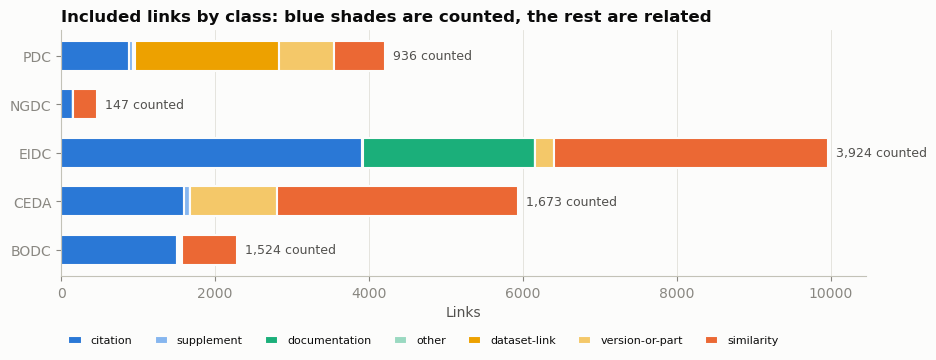

In [9]:
#@title Headline table and chart  { display-mode: "form" }
inc = L[L.status == "included"]
tab = pd.crosstab(inc.data_centre.replace("", "unknown"), inc.relation_class).reindex(columns=CLASSES, fill_value=0)
head = pd.DataFrame({
    "datasets": D.groupby(D.data_centre.replace("", "unknown")).size(),
    "cited (counted)": L[L.counted].groupby(L.data_centre.replace("", "unknown")).data_doi.nunique(),
    "counted citations": L[L.counted].groupby(L.data_centre.replace("", "unknown")).size(),
    "related links": inc[~inc.counted].groupby(inc.data_centre.replace("", "unknown")).size(),
    "excluded": L[L.status == "excluded"].groupby(L.data_centre.replace("", "unknown")).size(),
}).fillna(0).astype(int)
head["% datasets cited"] = (head["cited (counted)"] / head["datasets"]).map("{:.1%}".format)
head.loc["All"] = head.drop(columns="% datasets cited").sum().tolist() + [f"{head['cited (counted)'].sum() / max(head['datasets'].sum(), 1):.1%}"]
display(head)
display(Markdown("**Included links by class** (citation and supplement are counted; the rest are related)"))
display(tab)
head.to_csv(f"{OUTPUT_DIR}/headline_by_centre.csv")

t2 = tab.loc[[c for c in CENTRES if c in tab.index]]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
left = np.zeros(len(t2))
for k in CLASSES:
    if t2[k].sum() == 0:
        continue
    ax.barh(t2.index, t2[k], left=left, color=CLASS_COLOUR[k], label=k, height=0.62, edgecolor=SURFACE, linewidth=1.5)
    left += t2[k].values
for i, centre in enumerate(t2.index):
    n = int(t2.loc[centre, list(COUNTED_CLASSES)].sum())
    ax.text(left[i], i, f"  {n:,} counted", va="center", color=INK2, fontsize=9)
ax.set_title("Included links by class: blue shades are counted, the rest are related")
ax.set_xlabel("Links"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, ncol=7, fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.2), handlelength=1.2)
plt.tight_layout(); plt.show()

## 2b. Where counted citations come from

In [10]:
#@title Sources and agreement between them  { display-mode: "form" }
cnt = L[L.counted].copy()
cnt["n_sources"] = cnt.sources.map(len)
exploded = cnt.explode("sources").reset_index(drop=True)
display(Markdown("A citation found by two sources appears under both, so a row adds up to more than its counted citations."))
display(pd.crosstab(exploded.data_centre.replace("", "unknown"), exploded.sources))
display(Markdown("**Counted citations found by one source vs several** (several = independent confirmation)"))
display(pd.crosstab(cnt.data_centre.replace("", "unknown"), cnt.n_sources.clip(upper=3).map({1: "1 source", 2: "2 sources", 3: "3+ sources"})))
if not R["v4"]:
    display(Markdown("_v3 credits one source per row, so agreement between sources cannot be seen here._"))

A citation found by two sources appears under both, so a row adds up to more than its counted citations.

sources,crossref:datacitations,datacite,datacite:crossref,datacite:crossref-datacite,datacite:metadata,overton,scholexplorer
data_centre,,,,,,,
BODC,445,2,699,0,14,36,989
CEDA,1058,3,833,1,12,79,825
EIDC,605,1,1092,5,1496,172,2851
NGDC,68,0,59,0,0,10,101
PDC,384,0,336,0,199,4,503


**Counted citations found by one source vs several** (several = independent confirmation)

n_sources,1 source,2 sources,3+ sources
data_centre,,,
BODC,987,413,124
CEDA,809,590,274
EIDC,2265,1126,533
NGDC,84,35,28
PDC,541,303,92


## 2c. Exclusions

In [11]:
#@title Excluded links, by reason  { display-mode: "form" }
ex = L[L.status == "excluded"]
if len(ex):
    display(pd.crosstab(ex.data_centre.replace("", "unknown"), ex.reason, margins=True, margins_name="All"))
else:
    display(Markdown("_No excluded links at this source._"))
if not R["v4"] and len(ex):
    display(Markdown("_From `filtered_out_df.csv`. Legacy v3 did not record every row it removed, and gave no reason._"))

reason,comment,conference-abstract,gbif-download,peer-review,predates-data,All
data_centre,,,,,,
BODC,37,48,0,2,165,252
CEDA,39,55,0,2,0,96
EIDC,153,51,0,3,31,238
NGDC,0,29,0,0,0,29
PDC,43,19,4379,0,97,4538
All,272,202,4379,7,293,5153


## 2d. Metadata completeness of counted citing works

In [12]:
#@title What is missing, by data centre  { display-mode: "form" }
w = cnt.drop_duplicates(["data_doi", "citing_id"])
blank = lambda s: s.fillna("").astype(str).str.strip().str.lower().isin({""} | PLACEHOLDERS)
comp = pd.DataFrame({
    "counted citations": w.groupby("data_centre").size(),
    "no title": w[blank(w.title)].groupby("data_centre").size(),
    "no date": w[blank(w.issued)].groupby("data_centre").size(),
    "no citation string": w[blank(w.citation_text)].groupby("data_centre").size(),
}).fillna(0).astype(int)
for col in ["no title", "no date", "no citation string"]:
    comp[col] = comp[col].astype(str) + " (" + (comp[col] / comp["counted citations"]).map("{:.1%}".format) + ")"
display(comp)
if R["v4"]:
    display(Markdown("**Where citing-work metadata came from**"))
    display(pd.crosstab(w.data_centre, w.metadata_source.replace("", "none")))

,counted citations,no title,no date,no citation string
data_centre,,,,
BODC,1524,0 (0.0%),7 (0.5%),0 (0.0%)
CEDA,1673,0 (0.0%),3 (0.2%),0 (0.0%)
EIDC,3924,35 (0.9%),39 (1.0%),35 (0.9%)
NGDC,147,0 (0.0%),0 (0.0%),0 (0.0%)
PDC,936,38 (4.1%),38 (4.1%),38 (4.1%)


**Where citing-work metadata came from**

metadata_source,crossref,datacite,none,overton,scholexplorer
data_centre,,,,,
BODC,1412,35,0,34,43
CEDA,1544,32,0,79,18
EIDC,3441,106,35,175,167
NGDC,136,0,0,10,1
PDC,861,17,38,4,16


## 2e. Most-cited datasets

In [13]:
#@title Top datasets per data centre  { display-mode: "form" }
top = (cnt.groupby(["data_centre", "data_doi"]).size().rename("counted").reset_index()
          .sort_values(["data_centre", "counted"], ascending=[True, False]).groupby("data_centre").head(3))
top["title"] = top.data_doi.map(D.set_index("doi").title).map(lambda s: short(s, 70))
display(top.reset_index(drop=True))

,data_centre,data_doi,counted,title
0,BODC,10.5285/a29c5465-b138-234d-e053-6c86abc040b9,247,The GEBCO_2020 Grid - a continuous terrain model of the global oceans…
1,BODC,10.5285/c6612cbe-50b3-0cff-e053-6c86abc09f8f,152,The GEBCO_2021 Grid - a continuous terrain model of the global oceans…
2,BODC,10.5285/e0f0bb80-ab44-2739-e053-6c86abc0289c,135,The GEBCO_2022 Grid - a continuous terrain model of the global oceans…
3,CEDA,10.5285/58a8802721c94c66ae45c3baa4d814d0,52,CRU TS4.01: Climatic Research Unit (CRU) Time-Series (TS) version 4.0…
4,CEDA,10.5285/10d3e3640f004c578403419aac167d82,49,CRU TS4.03: Climatic Research Unit (CRU) Time-Series (TS) version 4.0…
5,CEDA,10.5285/58f00d8814064b79a0c49662ad3af537,47,ESA Fire Climate Change Initiative (Fire_cci): MODIS Fire_cci Burned …
6,EIDC,10.5285/6c6c9203-7333-4d96-88ab-78925e7a4e73,107,"Land Cover Map 2015 (vector, GB)"
7,EIDC,10.5285/bb15e200-9349-403c-bda9-b430093807c7,104,"Land Cover Map 2015 (25m raster, GB)"
8,EIDC,10.5285/507a5e1f-e056-454c-8ff6-d185f3da8556,86,"Water chemistry, hydrology and fluvial carbon data for two Amazonian …"
9,NGDC,10.5285/3b141dce-76fc-4c54-96fa-c232e98010ea,14,Biosphere Isotope Domains GB (V1): Interactive Website


## 2f. Citations over time (calendar year and UK fiscal year)

**All centres** — counted citations by UK fiscal year (Apr–Mar). 369 have no month, so no fiscal year.

fy,FY2019/20,FY2020/21,FY2021/22,FY2022/23,FY2023/24,FY2024/25,FY2025/26,FY2026/27
citations,498,604,869,1021,1081,1129,1248,434


**NGDC** — counted citations by UK fiscal year (Apr–Mar). 9 have no month, so no fiscal year.

fy,FY2019/20,FY2020/21,FY2021/22,FY2022/23,FY2023/24,FY2024/25,FY2025/26,FY2026/27
citations,7,10,13,28,18,18,25,15


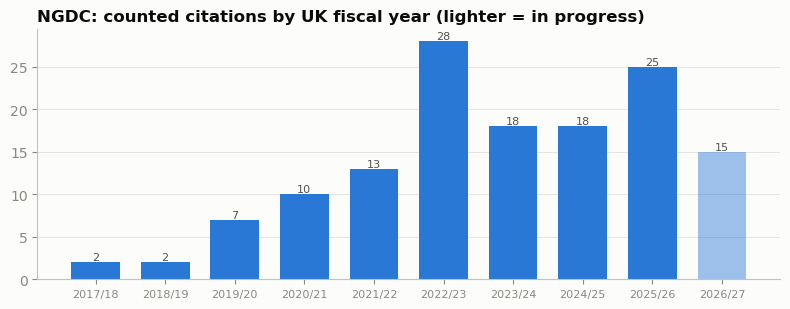

In [14]:
#@title Counted citations by year of the citing work  { display-mode: "form" }
f = cnt.copy()
f["year"] = pd.to_numeric(f.issued.str[:4], errors="coerce")
f["fy"] = f.issued.map(fy_label)
for scope, df in [("All centres", f), (FOCUS_CENTRE, f[f.data_centre == FOCUS_CENTRE])]:
    fy = df.dropna(subset=["fy"]).groupby("fy").size()
    display(Markdown(f"**{scope}** — counted citations by UK fiscal year (Apr–Mar). "
                     f"{int(df.fy.isna().sum())} have no month, so no fiscal year."))
    display(fy.tail(8).to_frame("citations").T)
fy = f[f.data_centre == FOCUS_CENTRE].dropna(subset=["fy"]).groupby("fy").size().tail(10)
if len(fy):
    cur = fy_label(date.today().isoformat())
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar(range(len(fy)), fy.values, color=[SERIES[0] if k != cur else SERIES[0] + "73" for k in fy.index], width=0.7)
    ax.set_xticks(range(len(fy))); ax.set_xticklabels([k.replace("FY", "") for k in fy.index], fontsize=8)
    for i, v in enumerate(fy.values):
        ax.text(i, v, f"{v}", ha="center", va="bottom", fontsize=8, color=INK2)
    ax.set_title(f"{FOCUS_CENTRE}: counted citations by UK fiscal year (lighter = in progress)")
    ax.grid(axis="x", visible=False)
    plt.tight_layout(); plt.show()

## 2g. New since a date

In [15]:
#@title Links first seen since NEW_SINCE  { display-mode: "form" }
latest = L.first_seen.max() if "last_seen" not in L else L.last_seen.max()
since = NEW_SINCE or (date.fromisoformat(latest[:10]) - timedelta(days=14)).isoformat()
new = L[L.first_seen >= since]
display(Markdown(f"First seen on or after **{since}**: {len(new):,} links, {int(new.counted.sum()):,} counted."))
display(pd.crosstab(new.data_centre.replace("", "unknown"), new.relation_class).reindex(columns=CLASSES, fill_value=0))
fn = new[(new.data_centre == FOCUS_CENTRE) & new.counted]
if len(fn):
    display(Markdown(f"**New counted citations for {FOCUS_CENTRE}**"))
    display(fn[["first_seen", "data_doi", "citing_id", "title", "issued"]]
            .assign(title=lambda d: d.title.map(short)).sort_values("first_seen", ascending=False).head(25))

First seen on or after **2026-09-23**: 25,124 links, 6,425 counted.

relation_class,citation,supplement,documentation,other,dataset-link,version-or-part,similarity
data_centre,,,,,,,
BODC,1713,24,0,1,18,19,723
CEDA,1600,76,5,0,0,1125,3161
EIDC,2621,14,2236,0,2,246,3557
NGDC,141,2,0,0,0,1,348
PDC,5233,61,43,1,771,714,668


**New counted citations for NGDC**

,first_seen,data_doi,citing_id,title,issued
17304,2026-10-07,10.5285/90aed6b4-4932-4a26-a07a-d78929dee65a,10.1016/j.envpol.2025.126371,Widespread pesticide pollution in two English river catchments of con…,2025-06
24838,2026-10-07,10.5285/e0df9db6-09ac-4fa3-a815-1394c1988654,10.1007/s10661-026-15918-6,Region-specific LOI–TOC conversion models for marine sediment blue ca…,2026-09-16
24017,2026-10-07,10.5285/d6b7c567-49f0-44c7-a94c-e82fa17ff98e,10.5194/cp-2022-87,Environmental changes during the onset of the Late Pliensbachian Even…,2022-11-30
6574,2026-10-07,10.5285/4cd1b2e2-1f8f-4f9b-9991-245122e078c0,10.1093/icesjms/fsag049,Estimating the extent and impact of bait use in a UK coastal fishery,2026-04-01
17871,2026-10-07,10.5285/97483c32-940a-42da-9e21-2e88bd8ff333,https://ec.europa.eu/research/participants/documents/downloadPublic?documentIds=080166...,Subsurface Evaluation of Carbon capture and storage and Unconventiona…,2022-02-24
357,2026-10-07,10.5285/04c9ea44-4388-4239-b31e-47566ee5fd37,10.1186/s13617-026-00167-6,PDCD-DAT – a global database of pyroclastic density current deposit f…,2026-05-11
4023,2026-10-07,10.5285/33054628-1276-4487-b9bd-cd5faa8a395c,10.1016/j.oregeorev.2017.06.031,Volcanological and environmental controls on the Snowdon mineralizati…,2017-10
23056,2026-10-07,10.5285/cdbca137-0bb3-4281-b872-399a4df8e946,10.1371/journal.pwat.0000486,Connecting narratives and numbers to investigate the interaction of s…,2026-02-17
23055,2026-10-07,10.5285/cdbca137-0bb3-4281-b872-399a4df8e946,10.1016/j.worlddev.2020.105286,Flesh and bones: Working with the grain to improve community manageme…,2021-02
22851,2026-10-07,10.5285/cb336b72-1978-4319-a591-c6ac42ffcd61,10.1144/sp527-2022-58,Unlocking national treasures: the core scanning approach,2023-03-30


---
# Part 3 — One dataset

In [16]:
#@title show_dataset(doi)  { display-mode: "form" }
def show_dataset(doi, links=None):
    links = L if links is None else links
    doi = doi.strip().lower()
    rows = links[links.data_doi == doi]
    title = D.set_index("doi").title.get(doi) if doi in set(D.doi) else (rows.data_title.iloc[0] if len(rows) else "")
    display(Markdown(f"### {doi}\n{title}"))
    cols = ["citing_id", "title", "issued", "relation_type", "sources", "first_seen"]
    cols = [c for c in cols if c in rows]
    for label, part in [("Counted citations", rows[rows.counted]),
                        ("Related links", rows[(rows.status == "included") & ~rows.counted]),
                        ("Excluded", rows[rows.status == "excluded"])]:
        if not len(part):
            continue
        extra = ["relation_class"] if label == "Related links" else (["reason"] if label == "Excluded" else [])
        display(Markdown(f"**{label}: {len(part)}**"))
        with pd.option_context("display.max_colwidth", 80):
            display(part[cols + extra].assign(title=lambda d: d.title.map(lambda s: short(s, 80))).sort_values("issued"))
    if R["v4"] and R["v4"]["reconciliation"] is not None:
        rc = R["v4"]["reconciliation"]
        hit = rc[rc.doi == doi]
        if len(hit):
            display(Markdown("**Against DataCite's citationCount**"))
            display(hit.T)


inspect = INSPECT_DOI or (cnt[cnt.data_centre == FOCUS_CENTRE].data_doi.value_counts().index[0]
                          if (cnt.data_centre == FOCUS_CENTRE).any() else cnt.data_doi.value_counts().index[0])
show_dataset(inspect)

### 10.5285/3b141dce-76fc-4c54-96fa-c232e98010ea
Biosphere Isotope Domains GB (V1):  Interactive Website

**Counted citations: 14**

,citing_id,title,issued,relation_type,sources,first_seen
4907,10.1126/sciadv.aau6078,Multi-isotope analysis reveals that feasts in the Stonehenge environs and ac...,2019-03,IsCitedBy,[scholexplorer],2026-09-30
4898,10.1007/s12520-019-00849-w,Strontium and oxygen isotope evidence for the origin and movement of cattle ...,2019-06-06,IsCitedBy,[scholexplorer],2026-09-30
4902,10.1038/s41598-019-55671-0,Feasting and Mobility in Iron Age Ireland: Multi-isotope analysis reveals th...,2019-12-24,IsCitedBy,[scholexplorer],2026-09-30
4900,10.1017/eaa.2020.22,Isotopic Evidence for Human Movement into Central England during the Early N...,2020-05-08,IsCitedBy,[scholexplorer],2026-09-30
4910,10.14324/111.444.ai.2022.11,Iso-Wetlands: unlocking wetland ecologies and agriculture in prehistory thro...,2022,IsCitedBy,[scholexplorer],2026-09-30
4899,10.1007/s12520-022-01509-2,The Bodies in the ‘Bog’: A Multi-Isotope Investigation of Individual Life-Hi...,2022-03-24,IsCitedBy,[scholexplorer],2026-09-30
4897,10.1007/978-3-031-25722-3_4,Common Ground: Investigating Land Use and Community Through Strontium Isotop...,2023,IsCitedBy,[scholexplorer],2026-09-30
4906,10.1098/rsos.220798,Provenancing antiquarian museum collections using multi-isotope analysis,2023-02,IsCitedBy,[scholexplorer],2026-09-30
4903,10.1038/s41598-023-30222-w,Comparison between strip sampling and laser ablation methods to infer season...,2023-03-03,IsCitedBy,[scholexplorer],2026-09-30
4901,10.1017/s0068113x23000235,Agriculture and Population: Occupation and Burials in the Extramural Area of...,2023-09-06,IsCitedBy,[scholexplorer],2026-09-30


**Against DataCite's citationCount**

,562
doi,10.5285/3b141dce-76fc-4c54-96fa-c232e98010ea
data_centre,NGDC
datacite_citation_count,0
datacite_links_harvested,0
missing_vs_datacite,0
datacite_links_counted,0
datacite_links_dataset_link,0
datacite_links_excluded,0
datacite_links_other_class,0
pipeline_counted,14


---
# Part 4 — Compare with another version

Set `COMPARE_DIR` (a folder) or `COMPARE_REF` (a git ref of the repository) in Settings. Counted
citations are compared like for like: a legacy v3 version is classified with the v4 rules first.

In [17]:
#@title Per-dataset changes  { display-mode: "form" }
if not (COMPARE_DIR or COMPARE_REF):
    display(Markdown("_Set COMPARE_DIR or COMPARE_REF in Settings to compare with another version._"))
    OLD = None
else:
    g2, label2 = fetcher(COMPARE_DIR or None, None if COMPARE_DIR else COMPARE_REF)
    R2 = load(g2, label2)
    OLD, _ = link_table(R2)
    display(Markdown(f"Comparing **{R['label']}** (new) with **{R2['label']}** (old, "
                     f"{'v4' if R2['v4'] else ('legacy v3' if R2['v3']['legacy'] else 'v3')})."))
    new_c = L[L.counted].groupby("data_doi").size().rename("new")
    old_c = OLD[OLD.counted].groupby("data_doi").size().rename("old")
    merged = pd.concat([new_c, old_c], axis=1).fillna(0).astype(int)
    merged["diff"] = merged["new"] - merged["old"]
    both = pd.concat([L, OLD]).drop_duplicates("data_doi").set_index("data_doi")
    merged["data_centre"] = merged.index.map(both.data_centre).fillna("").str.replace("^$", "unknown", regex=True)
    totals = merged.groupby("data_centre")[["old", "new", "diff"]].sum()
    totals["datasets gained citations"] = merged[merged["diff"] > 0].groupby("data_centre").size()
    totals["datasets lost citations"] = merged[merged["diff"] < 0].groupby("data_centre").size()
    display(totals.fillna(0).astype(int))
    display(Markdown("**How many datasets changed, by how much** (counted citations, new − old)"))
    display(pd.cut(merged["diff"], [-np.inf, -10, -2, -1, 0, 1, 9, np.inf],
                   labels=["≤ −10", "−9 to −2", "−1", "0", "+1", "+2 to +9", "+10 or more"], right=True)
            .value_counts().sort_index().to_frame("datasets").T)
    display(Markdown("**Biggest gains and losses**"))
    show = merged.assign(title=merged.index.map(both.data_title).map(lambda s: short(s, 60)))
    display(pd.concat([show[show["diff"] > 0].nlargest(TOP_N, "diff"), show[show["diff"] < 0].nsmallest(TOP_N, "diff")]))
    merged.to_csv(f"{OUTPUT_DIR}/compare_per_dataset.csv")

_Set COMPARE_DIR or COMPARE_REF in Settings to compare with another version._

In [18]:
#@title compare_dataset(doi): new, gone and unchanged citing works  { display-mode: "form" }
def compare_dataset(doi, counted_only=True):
    if OLD is None:
        display(Markdown("_Set COMPARE_DIR or COMPARE_REF first._"))
        return
    doi = doi.strip().lower()
    pick = (lambda t: t[(t.data_doi == doi) & t.counted]) if counted_only else (lambda t: t[t.data_doi == doi])
    a, b = pick(L).set_index("citing_id"), pick(OLD).set_index("citing_id")
    status = pd.Series("unchanged", index=a.index.union(b.index))
    status[~status.index.isin(b.index)] = "new"
    status[~status.index.isin(a.index)] = "gone"
    out = pd.DataFrame({"status": status,
                        "title": a.title.combine_first(b.title).reindex(status.index),
                        "class_now": a.relation_class.reindex(status.index),
                        "class_before": b.relation_class.reindex(status.index)})
    display(Markdown(f"### {doi}: {Counter(status).most_common()}"))
    with pd.option_context("display.max_colwidth", 90):
        display(out.assign(title=out.title.map(lambda s: short(s, 90))).sort_values(["status", "title"]))
    if counted_only:
        moved = OLD[(OLD.data_doi == doi) & ~OLD.counted & OLD.citing_id.isin(a.index)]
        if len(moved):
            display(Markdown(f"{len(moved)} of the new counted citations were in the old version as non-counted links."))


if OLD is not None:
    compare_dataset(inspect)